# Grouping patient testimonies by theme, step by step (unsupervised learning)

About 1,000 short texts in which people describe a health problem in their own words ("a short sprint brought on a
twinge in my thigh…"). Nobody has told us which problem each text is about. Can the computer **find groups of texts that
talk about the same thing** on its own?

This notebook is written for a reader who knows basic Python but has **no machine-learning background**. Every step has
the same structure: **What we do**, **Why**, **How it works** (plain words, intuition first), the **code** and its
**output**, then **How to read this output**, which interprets the numbers of *this* run.

**Privacy.** The CSV stays local (it is not in the repository). Because this notebook's outputs are published, it never
prints more than **two testimonies, cut to 80 characters**; clusters are described by their most important words only.

## 0. Setup

### Cell 1: every import of the notebook

All libraries are imported here, once, with what each one is used for. The project code lives in `src/textclust/`.

In [1]:
import sys                     # to add the project's src/ folder to the import path
import csv                     # to read the raw CSV lines before any cleaning (section 2)
import tempfile                # temporary folder for the "another CSV" demo (section 11)
from pathlib import Path       # file paths that work on every OS
from collections import Counter  # to count fields per line and words

import numpy as np             # arrays and maths
import pandas as pd            # tables (DataFrame)
import matplotlib.pyplot as plt  # every figure of the notebook

from sklearn.feature_extraction.text import TfidfVectorizer  # texts -> TF-IDF word weights
from sklearn.decomposition import TruncatedSVD               # LSA: compresses the TF-IDF table
from sklearn.preprocessing import normalize                  # L2 normalisation (vectors of length 1)
from sklearn.metrics.pairwise import cosine_similarity       # similarity between two texts
from sklearn.cluster import KMeans, HDBSCAN                  # the two clustering algorithms
from sklearn.metrics import silhouette_score, silhouette_samples  # quality of a clustering without labels

# Project modules (src/textclust). Works when the notebook runs from unsupervised_learning/ or from the repo root.
REPO = Path.cwd() if (Path.cwd() / "src" / "textclust").exists() else Path.cwd().parent
sys.path.insert(0, str(REPO / "src"))
from textclust import io as tio            # CSV loading with automatic detection
from textclust import clean as tclean      # text normalisation, filtering, language detection
from textclust import features as tfeat    # TF-IDF bounds derived from the corpus size
from textclust import model as tmodel      # k range, K-Means vs HDBSCAN selection
from textclust import report as treport    # top terms per cluster, 2-D projection
from textclust import pipeline as tpipe    # the whole chain in one call (section 11)

plt.rcParams.update({"figure.dpi": 80})
%config InlineBackend.figure_formats = ["png"]
print("pandas", pd.__version__, "| numpy", np.__version__)

pandas 3.1.1 | numpy 2.5.4


### Cell 2: parameters

| Name | Meaning |
|---|---|
| `CSV_PATH` | The file to cluster. `Student_Dataset.csv` is local and git-ignored. |
| `TEXT_COLUMN` | Column holding the texts (name or 0-based index). `None` = detected automatically. |
| `LABEL_COLUMN` | Optional column of known categories, used only to *check* the clusters afterwards. `None` = detect, `False` = none. |
| `SEED` | Seed of every random choice (SVD, K-Means starting points, t-SNE): same seed, same results. |
| `MAX_COMPONENTS` | Number of dimensions kept by the SVD (section 5). |
| `K_MAX_CAP` | Largest number of clusters tried by K-Means (section 7). |
| `MAX_NOISE` | HDBSCAN is rejected if it leaves more than this share of texts unassigned (section 8). |

In [2]:
CSV_PATH = REPO / "unsupervised_learning" / "Student_Dataset.csv"
TEXT_COLUMN = None
LABEL_COLUMN = None
SEED = 42
MAX_COMPONENTS = 100
K_MAX_CAP = 20
MAX_NOISE = 0.3

def short(text, n=80):
    # Never show a full testimony: first n characters only
    return text if len(text) <= n else text[:n - 1] + "…"

print("CSV found:", CSV_PATH.exists(), "| size:", round(CSV_PATH.stat().st_size / 1024), "KB")

CSV found: True | size: 158 KB


## 1. The goal: supervised vs unsupervised learning

**What we do.** Nothing in code yet: we set the goal.

**Why.** It decides what "a good result" means.

**How it works.**

| | Supervised learning | Unsupervised learning (this notebook) |
|---|---|---|
| Data | examples **with the answer** (e.g. an X-ray + "OA / no OA") | examples **without any answer** |
| Task | learn to predict the answer for new examples | find structure: groups of similar examples (**clusters**) |
| How we judge it | compare predictions with the true answers (accuracy, recall…) | no true answer: internal measures (how compact and separated the groups are) **and human reading** of each group |

The plan: turn each text into numbers (sections 3–6), group nearby texts (sections 7–8), then read the groups and name
their themes (sections 9–10).

## 2. Loading the CSV: what is detected automatically

**What we do.** Read the file without being told its format, and find which column holds the texts.

**Why.** The tool must work on *any* CSV of texts: different encodings, separators, with or without a header, and
sometimes broken lines. Guessing wrong would silently cluster ids instead of texts.

**How it works** (`tio.load_csv`):
- **Encoding** (how characters are stored as bytes): try UTF-8 with BOM, UTF-8, then Latin-1, keep the first that decodes.
- **Delimiter**: Python's `csv.Sniffer` on the first 50 lines, otherwise the separator (`, ; tab |`) whose count per line
  is the most regular.
- **Header**: yes if the first row looks like short column names and the rows below look different (numbers, long texts).
- **Ragged rows** (fewer or more fields than the others): a short row's longest field is the text, the other values fill
  the other columns; a long row has unquoted commas inside its text, so the surplus is glued back into the text.
- **Text column**: the column with the longest values made mostly of letters.
- **Label column**: a column with few distinct values (between 2 and √n), not an id, not constant.
- **Language** (detected during cleaning): the share of words that are English or French stop words ("the", "and", "le", "et"…).

In [3]:
with open(CSV_PATH, encoding="utf-8-sig", newline="") as f:
    raw_rows = list(csv.reader(f))
fields_per_row = Counter(len(r) for r in raw_rows)
print("raw lines:", len(raw_rows), "| fields per line:", dict(fields_per_row))
print("first fields of 4 lines (texts hidden):", [r[:-1] for r in raw_rows[:4]])

loaded = tio.load_csv(CSV_PATH, text_column=TEXT_COLUMN, label_column=LABEL_COLUMN)
p = loaded.profile
display(pd.DataFrame({"detected": [p["encoding"], repr(p["delimiter"]), p["header"], p["columns"], p["rows"],
                                   p["ragged_rows_repaired"], p["text_column"], p["label_column"], p["constant_columns"]]},
                     index=["encoding", "delimiter", "header row", "columns", "rows", "ragged rows repaired",
                            "text column", "label column", "constant columns"]))

df = loaded.frame
TEXT = loaded.text_column
view = df.drop(columns=TEXT).assign(text_length=df[TEXT].str.len())     # texts replaced by their length
display(view.head())
print("values of col1:", df["col1"].value_counts(dropna=False).to_dict())

raw lines: 1011 | fields per line: {2: 397, 3: 614}
first fields of 4 lines (texts hidden): [['1'], ['2', '0x000000'], ['3', '0x000000'], ['4']]


,detected
encoding,utf-8-sig
delimiter,"','"
header row,False
columns,"[col0, col1, col2]"
rows,1011
ragged rows repaired,"{'short': 397, 'long': 0}"
text column,col2
label column,None
constant columns,[col1]


,col0,col1,text_length
0,1,NaN,125
1,2,0x000000,175
2,3,0x000000,133
3,4,NaN,130
4,5,0x000000,109


values of col1: {'0x000000': 614, nan: 397}


#### How to read this output


- The raw file has **1,011 lines**, but they do not all have the same shape: **614 lines have 3 fields** (id, `0x000000`,
  text) and **397 have only 2** (id, text). A naive loader would put the text of those 397 lines in the wrong column.
- The loader found **UTF-8 with BOM**, delimiter **`,`**, **no header row** (the first line is already data), so the
  columns are named `col0`, `col1`, `col2`. The **397 short rows were repaired**: their text was moved to `col2` and
  `col1` left empty (`NaN`).
- **Text column = `col2`** (long, mostly letters). `col1` only ever contains `0x000000` (614 times) or nothing: it is
  **constant** and carries no information. **No label column** was found, so there is no "true answer" to compare with.
- The texts are 109 to 175 characters long in the first rows (the texts themselves are hidden).

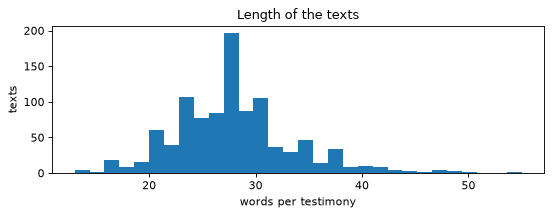

{'count': 1011.0, 'mean': 27.9, 'std': 5.6, 'min': 13.0, '25%': 24.0, '50%': 27.0, '75%': 30.0, 'max': 55.0}


In [4]:
lengths_words = df[TEXT].str.split().str.len()
fig, ax = plt.subplots(figsize=(7, 2.8))
ax.hist(lengths_words, bins=30, color="tab:blue")
ax.set_xlabel("words per testimony"); ax.set_ylabel("texts"); ax.set_title("Length of the texts")
plt.tight_layout(); plt.show()
print(lengths_words.describe().round(1).to_dict())

#### How to read this output


- The testimonies are short and regular: **27 words** in the median, half of them between 24 and 30 words, from 13 to 55.
- Short texts mean few words per text: each text will use only a handful of the vocabulary's words (section 4).

## 3. Cleaning the texts

**What we do.** Normalise every text, then drop the texts that are empty, too short (fewer than 2 words) or duplicated.

**Why.** For the computer, "Knee", "knee" and "knee," are three different strings. Cleaning makes the same word look the
same everywhere. Duplicates would count twice and pull a cluster towards them; empty texts carry no information.

**How it works** (`tclean.normalize`): Unicode normalisation (the same character always has the same code), lowercase,
remove URLs, digits and punctuation (apostrophes become spaces), squeeze spaces. Accented letters are kept (useful for
French). Then `tclean.clean_corpus` filters the rows and detects the language.

In [5]:
data, clean_report = tclean.clean_corpus(df, TEXT, min_tokens=2)
display(pd.Series(clean_report, name="value").to_frame())

# Before / after on two examples (cut to 80 characters)
for i in [0, 3]:
    print("before:", short(df[TEXT].iloc[i]))
    print("after :", short(tclean.normalize(df[TEXT].iloc[i])), "\n")

,value
input_rows,1011
dropped_empty,0
dropped_too_short,0
dropped_duplicates,17
kept,994
min_tokens,2
language,en
stop_word_share,"{'en': 0.5304, 'fr': 0.0926}"


before: On uneven paths the heel feels wobbly side‑to‑side. Slanted pavements bring a q…
after : on uneven paths the heel feels wobbly side to side slanted pavements bring a qu… 

before: A short sprint brought on a twinge in the middle of the back of my thigh. It’s …
after : a short sprint brought on a twinge in the middle of the back of my thigh it s t… 



#### How to read this output


- **1,011 rows in, 994 kept.** Nothing was empty or shorter than 2 words; **17 exact duplicates** (identical after
  cleaning) were removed.
- **Language = English**: 53 % of the words are English stop words against 9 % French ones, a clear margin.
- In the two examples, capitals become lowercase, the special hyphen of "side‑to‑side" and the punctuation become spaces,
  and "It’s" becomes "it s" (the lone `s` is later removed as a stop word).

## 4. TF-IDF: turning texts into numbers

**What we do.** Describe each text by a list of word weights: one column per word of the vocabulary.

**Why.** Clustering algorithms need numbers. Counting words is the simplest idea, but very common words ("pain",
"feel") appear everywhere and say little about the topic, while rarer words ("wheeze", "blister") are very telling.

**How it works.** TF-IDF = **term frequency × inverse document frequency**:
- **TF**: how many times the word appears in *this* text.
- **IDF**: how rare the word is in the whole corpus. scikit-learn uses `idf = ln((1 + n) / (1 + df)) + 1`, where `n` is
  the number of texts and `df` the number of texts containing the word. A word present everywhere gets the minimum, 1;
  a rare word gets more.
- The weight is TF × IDF; each text's row is then scaled to length 1, so long and short texts are comparable.
- **Stop words** ("the", "and", "my"…) are removed first, they carry no topic.

A toy example with three sentences:

In [6]:
toy = ["my knee hurts when walking",
       "my head hurts at night",
       "itchy rash on my arm at night"]
toy_vec = TfidfVectorizer()                               # no stop words here, to see "my" being down-weighted
toy_tfidf = toy_vec.fit_transform(toy)
display(pd.DataFrame({"texts containing it (df)": np.asarray((toy_tfidf > 0).sum(0)).ravel(),
                      "idf": toy_vec.idf_.round(3)}, index=toy_vec.get_feature_names_out()).T)
display(pd.DataFrame(toy_tfidf.toarray().round(2), columns=toy_vec.get_feature_names_out(),
                     index=["sentence 1", "sentence 2", "sentence 3"]))

,arm,at,head,hurts,itchy,knee,my,night,on,rash,walking,when
texts containing it (df),1.000,2.000,1.000,2.000,1.000,1.000,3.0,2.000,1.000,1.000,1.000,1.000
idf,1.693,1.288,1.693,1.288,1.693,1.693,1.0,1.288,1.693,1.693,1.693,1.693


,arm,at,head,hurts,itchy,knee,my,night,on,rash,walking,when
sentence 1,0.00,0.00,0.00,0.38,0.00,0.5,0.30,0.00,0.00,0.00,0.5,0.5
sentence 2,0.00,0.43,0.57,0.43,0.00,0.0,0.34,0.43,0.00,0.00,0.0,0.0
sentence 3,0.43,0.32,0.00,0.00,0.43,0.0,0.25,0.32,0.43,0.43,0.0,0.0


#### How to read this output


- `my` appears in all 3 sentences: its IDF is the minimum, **1.0**. Words present in 2 sentences (`at`, `hurts`, `night`)
  get **1.288**; words present in only one (`knee`, `rash`, `head`…) get the highest value, **1.693**.
- In the weight table, sentence 1 is described mostly by **`knee`, `walking`, `when` (0.50 each)**, while `my` only gets
  0.30: the rare, topical words dominate. Sentences 2 and 3 share `at` and `night`, so they will look a bit similar;
  sentence 1 shares only `my` and `hurts` with sentence 2.

On the real corpus, two extra filters remove words that cannot help grouping texts:
- **`min_df`**: a word must appear in at least `min_df` texts. A word used once cannot link two texts together.
- **`max_df`**: a word present in more than this share of texts is dropped: it is almost a stop word for this corpus.

`tfeat.tfidf_bounds(n)` derives both from the corpus size `n`: `min_df` = 1, 2, 3 or 5 as `n` grows (below 50, 2,000,
10,000 texts); `max_df` = 0.95 for very small corpora, 0.8 otherwise.

In [7]:
texts = data["clean_text"]
n_docs = len(texts)
min_df, max_df = tfeat.tfidf_bounds(n_docs)
stop_words = tclean.stop_words_for(clean_report["language"])
vectorizer = TfidfVectorizer(min_df=min_df, max_df=max_df, stop_words=stop_words)
tfidf = vectorizer.fit_transform(texts)
vocab = vectorizer.get_feature_names_out()

all_words = Counter(w for t in texts for w in t.split())
print(f"{n_docs} texts -> min_df={min_df}, max_df={max_df}, {len(stop_words)} stop words")
print(f"distinct words before filtering: {len(all_words)} | kept vocabulary: {len(vocab)}")
print(f"TF-IDF table: {tfidf.shape} | non-zero cells: {tfidf.nnz} ({tfidf.nnz / np.prod(tfidf.shape):.2%})")

doc_freq = np.asarray((tfidf > 0).sum(0)).ravel()
order = np.argsort(doc_freq)
display(pd.DataFrame({"most frequent words": vocab[order[::-1][:8]], "in % of texts": (100 * doc_freq[order[::-1][:8]] / n_docs).round(1),
                      "rarest kept words": vocab[order[:8]], "in n texts": doc_freq[order[:8]]}))

994 texts -> min_df=2, max_df=0.8, 336 stop words
distinct words before filtering: 2331 | kept vocabulary: 1271
TF-IDF table: (994, 1271) | non-zero cells: 12338 (0.98%)


,most frequent words,in % of texts,rarest kept words,in n texts
0,feel,25.8,wrong,2
1,feels,16.9,workday,2
2,pain,13.2,ahead,2
3,like,11.9,whistly,2
4,sore,11.3,arch,2
5,ache,10.4,antibiotic,2
6,makes,10.1,backpack,2
7,chest,9.4,actual,2


#### How to read this output


- With **994 texts**, the rule gives **`min_df = 2`** and **`max_df = 0.8`**; 336 English stop words are removed.
- The corpus contains **2,331 distinct words**; **1,271 are kept**. Most of the dropped ones appear in a single text.
  No word reaches 80 % of the texts, so `max_df` removed nothing here.
- The table has 994 rows × 1,271 columns, but only **0.98 % of its cells are non-zero** (about 12 words per text).
- The most frequent words (`feel` 25.8 %, `feels`, `pain`, `like`) are vague; the rarest kept words appear in only
  2 texts. Neither extreme says much about a theme: the useful words are in between.

## 5. LSA: compressing the vocabulary with a truncated SVD

**What we do.** Replace the ~1,300 word columns by **100 "topic" columns**.

**Why.** The TF-IDF table is huge and almost empty (each text uses ~10 of the ~1,300 words). Two texts that say the same
thing with different words ("breathless" vs "short of breath") share no column, so they look unrelated. Distances in
such a sparse, high-dimensional table are also unreliable for clustering.

**How it works.** **Latent Semantic Analysis (LSA)** applies a **truncated Singular Value Decomposition (SVD)** to the
TF-IDF table. It finds the combinations of words that tend to **appear together** ("chest + tightness + breathe")
and uses each combination as a new axis. Each text is then described by how much it uses each of these 100 combinations.
Words that co-occur end up close to each other, so synonyms partly merge. The **explained variance** tells how much of the
information of the TF-IDF table the 100 axes keep. (SVD is PCA's cousin; unlike PCA, it works directly on a sparse table.)

reduced table: (994, 100) | variance kept by 100 components: 41.5%


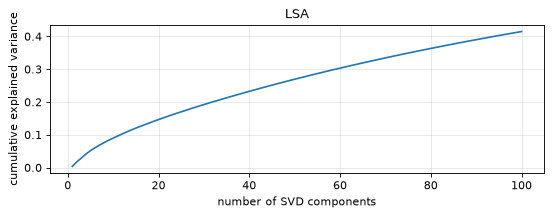

,component 2,component 3,component 4,component 5,component 6
0,throat,pain,feel,itchy,hot
1,cold,ear,pain,rash,skin
2,mild,sharp,vision,hot,blister
3,nose,head,notice,red,touched
4,ear,throbbing,throbbing,new,red
5,fever,ache,ear,blister,hand


In [8]:
n_comp = min(MAX_COMPONENTS, tfidf.shape[1] - 1, n_docs - 1)
svd = TruncatedSVD(n_components=n_comp, random_state=SEED)
Z = svd.fit_transform(tfidf)
cum = np.cumsum(svd.explained_variance_ratio_)
print("reduced table:", Z.shape, f"| variance kept by {n_comp} components: {cum[-1]:.1%}")

fig, ax = plt.subplots(figsize=(7, 2.8))
ax.plot(np.arange(1, n_comp + 1), cum); ax.grid(alpha=0.3)
ax.set_xlabel("number of SVD components"); ax.set_ylabel("cumulative explained variance"); ax.set_title("LSA")
plt.tight_layout(); plt.show()

display(pd.DataFrame({f"component {i + 1}": vocab[np.argsort(-svd.components_[i])[:6]] for i in range(1, 6)}))

#### How to read this output


- The 994 × 1,271 table becomes **994 × 100**. These 100 components keep **41.5 %** of the variance: the curve keeps
  rising slowly, because short texts with many different words do not compress well. 41.5 % is enough to group texts by
  their main words, while dropping rare, idiosyncratic words.
- Component 1 (not shown) is the "average text". The next ones are already readable themes: **2 = cold / throat / nose /
  fever**, **3 = ear / sharp / head pain**, **5 = itchy rash**, **6 = hot / skin / blister** (burns). LSA found topics
  without being told any.

## 6. L2 normalisation and cosine similarity

**What we do.** Scale every text vector to length 1, so that comparing two texts means comparing their **directions**.

**Why.** A long testimony has bigger numbers than a short one about the same problem. We want "same topic" to mean
"close", whatever the length.

**How it works.** **L2 normalisation** divides each vector by its length `√(x₁² + x₂² + …)`. The **cosine similarity**
of two texts is the cosine of the angle between their vectors: 1 = same direction (same words in the same proportions),
0 = nothing in common. Once vectors have length 1, the ordinary (Euclidean) distance used by K-Means is directly linked to
the cosine: `distance² = 2 × (1 − cosine)`. So K-Means on normalised vectors groups texts by cosine similarity.

lengths before: [0.656 0.6   0.588 0.58  0.712] | after: [1. 1. 1. 1. 1.]
text 0 and its nearest neighbour 535: cosine 0.905, distance² 0.189 = 2 × (1 − 0.905)


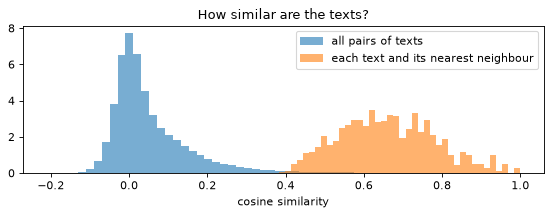

median similarity: all pairs 0.022 | nearest neighbour 0.655


In [9]:
embedding = normalize(Z, norm="l2")
print("lengths before:", np.linalg.norm(Z, axis=1)[:5].round(3), "| after:", np.linalg.norm(embedding, axis=1)[:5].round(3))

sims = cosine_similarity(embedding)
np.fill_diagonal(sims, np.nan)
nearest = np.nanmax(sims, axis=1)
a, b = 0, int(np.nanargmax(sims[0]))
d2 = np.sum((embedding[a] - embedding[b]) ** 2)
print(f"text {a} and its nearest neighbour {b}: cosine {sims[a, b]:.3f}, distance² {d2:.3f} = 2 × (1 − {sims[a, b]:.3f})")

fig, ax = plt.subplots(figsize=(7, 2.8))
ax.hist(sims[~np.isnan(sims)], bins=60, alpha=0.6, density=True, label="all pairs of texts")
ax.hist(nearest, bins=40, alpha=0.6, density=True, label="each text and its nearest neighbour")
ax.set_xlabel("cosine similarity"); ax.legend(); ax.set_title("How similar are the texts?")
plt.tight_layout(); plt.show()
print(f"median similarity: all pairs {np.nanmedian(sims):.3f} | nearest neighbour {np.median(nearest):.3f}")

#### How to read this output


- After normalisation every vector has length **1.0** (they were around 0.6–0.7 before).
- Text 0 and its nearest neighbour (text 535) have cosine **0.905**, and their squared distance is **0.189 = 2 × (1 − 0.905)**:
  the formula holds, so K-Means' distances are cosine similarities in disguise.
- Two random texts are almost unrelated (median cosine **0.022**, the blue peak near 0), but almost every text has a close
  neighbour (median **0.655**, orange): the corpus is made of small groups of similar texts, which is what clustering needs.

## 7. K-Means and the choice of k

**What we do.** Split the texts into *k* groups with **K-Means**, for every *k* from 2 to 20, and keep the *k* with the
best **silhouette**.

**Why.** K-Means is simple, fast and gives every text a group. But it needs *k*, the number of groups, which we do not
know: we must choose it from the data.

**How it works.**
- **K-Means**: (1) place *k* points, the **centroids**, at random; (2) assign each text to its nearest centroid;
  (3) move each centroid to the mean of its texts; repeat (2)–(3) until nothing changes. It is restarted 10 times from
  different starting points (`n_init=10`), keeping the best result. The figure below shows the iterations on toy 2-D data.
- **Inertia**: the sum of squared distances from each text to its centroid. It always decreases when *k* grows (more
  centroids = closer), so we look for an **elbow** where adding clusters stops helping much.
- **Silhouette** of a text: `(b − a) / max(a, b)`, where *a* is its average distance to the texts of its own cluster and
  *b* to the texts of the nearest other cluster. Near 1 = well inside its cluster, near 0 = on a border, negative = probably
  in the wrong cluster. The average silhouette (here with cosine distance) measures the whole clustering; we pick the *k*
  that maximises it. `tmodel.k_range(n)` caps *k* at `min(20, max(3, √(n/2)))`.

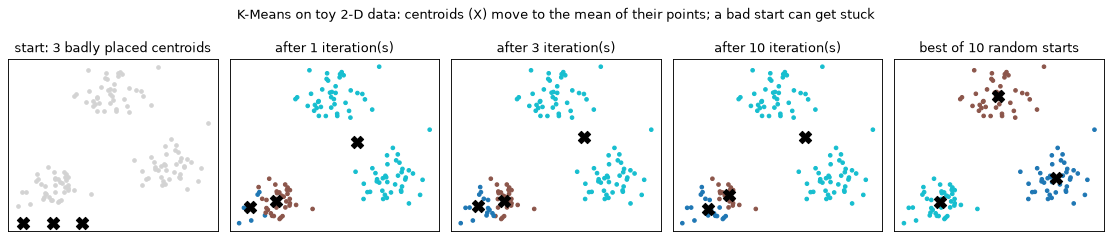

In [10]:
rng = np.random.default_rng(SEED)
blobs = np.vstack([rng.normal(c, 0.6, size=(40, 2)) for c in [(0, 0), (4, 1), (2, 4)]])
start = np.array([[-1.0, -1.5], [0.0, -1.5], [1.0, -1.5]])        # deliberately bad starting centroids
fig, axes = plt.subplots(1, 5, figsize=(14, 3))
for a_, iters in zip(axes, [0, 1, 3, 10, "restarts"]):
    if iters == 0:
        a_.scatter(*blobs.T, c="lightgrey", s=10); centers = start; a_.set_title("start: 3 badly placed centroids")
    elif iters == "restarts":
        km_toy = KMeans(n_clusters=3, n_init=10, random_state=SEED).fit(blobs)
        a_.scatter(*blobs.T, c=km_toy.labels_, cmap="tab10", s=10); centers = km_toy.cluster_centers_
        a_.set_title("best of 10 random starts")
    else:
        km_toy = KMeans(n_clusters=3, init=start, n_init=1, max_iter=iters).fit(blobs)
        a_.scatter(*blobs.T, c=km_toy.labels_, cmap="tab10", s=10); centers = km_toy.cluster_centers_
        a_.set_title(f"after {iters} iteration(s)")
    a_.scatter(*centers.T, c="black", marker="X", s=120); a_.set_xticks([]); a_.set_yticks([])
fig.suptitle("K-Means on toy 2-D data: centroids (X) move to the mean of their points; a bad start can get stuck")
plt.tight_layout(); plt.show()

#### How to read this output


- From a bad start (all 3 centroids at the bottom), after 1 iteration two centroids share the bottom-left blob and the third
  sits **between** the two other blobs. After 3 and 10 iterations nothing changes: K-Means is **stuck in a bad solution**
  (it only ever moves centroids a little, towards nearby points).
- The last panel uses **10 random starts and keeps the best** (lowest inertia): each blob gets its own centroid. This is
  why the project runs K-Means with `n_init=10`.

k tried: [2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20]


k,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20
inertia,916.4831,895.4312,876.6975,859.5758,844.4632,831.9559,821.0137,811.0116,799.8610,792.7425,780.7581,772.2825,766.2332,757.667,751.459,748.1483,740.4412,736.2915,729.1570
silhouette,0.0486,0.0615,0.0690,0.0753,0.0826,0.0920,0.0979,0.0984,0.1059,0.1038,0.1150,0.1197,0.1164,0.122,0.123,0.1161,0.1248,0.1194,0.1247


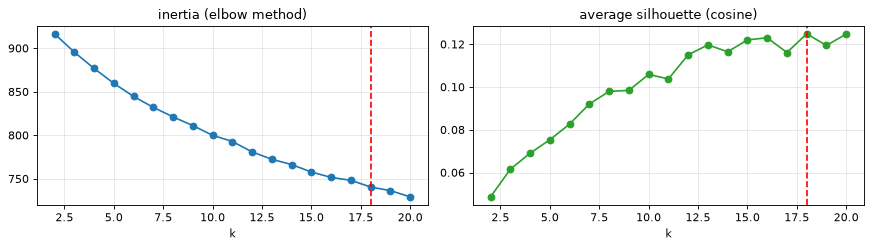

best k by silhouette: 18


In [11]:
print("k tried:", list(tmodel.k_range(n_docs, K_MAX_CAP)))
choice = tmodel.select_model(embedding, random_state=SEED, k_max_cap=K_MAX_CAP, max_noise=MAX_NOISE)
curve = pd.DataFrame(choice.k_curve).set_index("k")
display(curve[["inertia", "silhouette"]].round(4).T)

fig, axes = plt.subplots(1, 2, figsize=(11, 3.2))
axes[0].plot(curve.index, curve["inertia"], "o-"); axes[0].set_title("inertia (elbow method)")
axes[1].plot(curve.index, curve["silhouette"], "o-", color="tab:green"); axes[1].set_title("average silhouette (cosine)")
k_best = choice.candidates["kmeans"]["k"]
for a_ in axes: a_.axvline(k_best, color="red", ls="--"); a_.set_xlabel("k"); a_.grid(alpha=0.3)
plt.tight_layout(); plt.show()
print("best k by silhouette:", k_best)

#### How to read this output


- *k* from **2 to 20** was tried (the cap of 20 applies: √(994/2) ≈ 22).
- **Inertia** falls steadily from 916 (k = 2) to 729 (k = 20) with **no clear elbow**: the elbow method cannot decide here.
- **Silhouette** rises from 0.049 to about 0.12 and flattens after k ≈ 12. The maximum is at **k = 18 (0.1248)**, with
  k = 20 practically equal (0.1247) and k = 16 close (0.123).
- A silhouette of 0.12 is **low** (1 would be perfect): the groups exist but touch each other, as expected for short
  testimonies where symptoms overlap (a cough with a fever, a skin burn with blisters…).

## 8. HDBSCAN: a density-based alternative, and why it was rejected here

**What we do.** Run **HDBSCAN** on the same vectors and compare it with K-Means.

**Why.** K-Means has two weaknesses: we must give *k*, and it forces **every** text into a group, even an odd one.
HDBSCAN needs no *k* and can say "this text belongs to no group".

**How it works.** HDBSCAN looks for **dense regions**: places where many texts are close together. It grows clusters from
the densest areas and keeps those that stay stable over a range of density levels. Texts in sparse areas are labelled
**noise** (`-1`). Its main setting is `min_cluster_size` (here about 2 % of the corpus, `tmodel.hdbscan_min_cluster_size`).

**The selection rule** (`tmodel.select_model`): keep the method with the best silhouette, **but only among those that
leave at most `MAX_NOISE` = 30 % of texts as noise**. Without that rule, HDBSCAN could "win" by throwing away every
difficult text and scoring only the easy ones.

In [12]:
mcs = tmodel.hdbscan_min_cluster_size(n_docs)
hd = HDBSCAN(min_cluster_size=mcs, copy=True).fit(embedding)
hd_sizes = pd.Series(hd.labels_).value_counts().sort_index().rename(index={-1: "noise (-1)"})
print(f"min_cluster_size = {mcs} | HDBSCAN groups: {dict(hd_sizes)}")
display(pd.DataFrame(choice.candidates).T[["n_clusters", "noise_ratio", "silhouette", "eligible"]])
print("chosen:", choice.algorithm, "with", choice.n_clusters, "clusters")

min_cluster_size = 20 | HDBSCAN groups: {'noise (-1)': np.int64(767), 0: np.int64(30), 1: np.int64(56), 2: np.int64(141)}


,n_clusters,noise_ratio,silhouette,eligible
kmeans,18,0.0,0.124845,True
hdbscan,3,0.7716,0.160943,False


chosen: kmeans with 18 clusters


#### How to read this output


- With `min_cluster_size = 20` (2 % of 994), HDBSCAN finds only **3 groups (30, 56 and 141 texts)** and labels
  **767 texts as noise: 77 %**.
- Its silhouette is higher (**0.161 vs 0.125**), but measured only on the 23 % of texts it kept, the easy ones.
- Its noise ratio is far above the 30 % limit, so it is **not eligible**, and **K-Means with 18 clusters** is chosen.
  The reason is visible in section 6: texts are spread thinly in 100-D with few really dense areas, which is a hard case
  for density-based clustering.

## 9. Results: the clusters and their themes

**What we do.** Measure each cluster's size and list its **most important words**, then name its theme.

**Why.** Numbers alone (silhouette) cannot tell whether the groups make sense. A human must read them. Words are the
safest summary: they describe the group without exposing any individual testimony.

**How it works.** For each cluster, we average the TF-IDF rows of its texts (the cluster's centroid in word space) and
take the 8 words with the highest average weight (`treport.top_terms`). The per-cluster silhouette tells which groups
are clear-cut and which are fuzzy.

,size,mean silhouette,top words
cluster,,,
0,47,0.259,"hot, blister, touched, small, red, skin, hand, swollen"
1,54,0.208,"felt, nose, throat, mild, day, congestion, cold, headache"
2,96,-0.040,"especially, feel, vision, feeling, night, eye, notice, gums"
3,29,0.152,"ankle, heel, toes, sore, uneven, squeeze, walking, inner"
4,46,0.121,"breath, breathing, short, catch, cough, walking, cold, air"
5,66,0.237,"itchy, rash, new, hives, raised, spots, welts, spread"
6,51,0.175,"feel, pale, headaches, skin, looks, dizzy, heart, notice"
7,60,0.205,"ear, pain, fever, hear, cold, slight, right, hearing"
8,57,0.103,"wrist, elbow, forearm, hand, palm, feels, finger, brings"


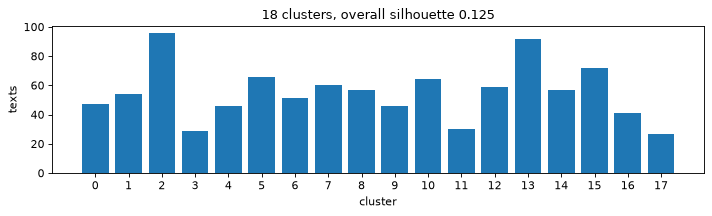

In [13]:
labels = choice.labels
terms = treport.top_terms(tfidf, labels, vectorizer, n_terms=8)
sil = silhouette_samples(embedding, labels, metric="cosine")
clusters = pd.DataFrame({"size": pd.Series(labels).value_counts().sort_index(),
                         "mean silhouette": pd.Series(sil).groupby(labels).mean().round(3),
                         "top words": pd.Series({c: ", ".join(w) for c, w in terms.items()})}).rename_axis("cluster")
pd.set_option("display.max_colwidth", 90)
display(clusters)

fig, ax = plt.subplots(figsize=(9, 2.8))
ax.bar(clusters.index.astype(str), clusters["size"]); ax.set_xlabel("cluster"); ax.set_ylabel("texts")
ax.set_title(f"{choice.n_clusters} clusters, overall silhouette {choice.scores['silhouette']:.3f}")
plt.tight_layout(); plt.show()

#### How to read this output


- Sizes range from **27 to 96 texts**; no cluster is empty or swallows the corpus.
- Most clusters have a clear theme in their words: **0 burns** (hot, blister, touched), **1 common cold** (nose,
  congestion, headache), **3 ankle/heel**, **4 shortness of breath**, **5 itchy rash/hives**, **7 ear pain/hearing**,
  **8 wrist/elbow/hand**, **9 shoulder**, **10 chest tightness/wheeze**, **11 knee**, **12 headache**, **13 hip/leg/groin**,
  **14 dry cough with fever**, **15 sun/skin blisters**, **16 blood sugar/blood pressure/weight loss**, **17 foot/big toe**.
- The fuzzy ones: **cluster 2** (96 texts, silhouette **−0.040**) mixes vision, eyes, gums and night symptoms with vague words
  ("especially", "feel"): it is a catch-all of texts that fit nowhere else. **Cluster 6** (pale, dizzy, heart) and
  **13 / 15** (silhouettes 0.010 and −0.006) are also borderline.
- The clearest groups (silhouette > 0.25) are **16 (blood/sugar), 0 (burns), 17 (foot) and 5 (rash)**: specific vocabulary.
- Some themes are split in two (two respiratory groups 1 and 14, two skin groups 0 and 15): with a lower *k*, they would merge.

## 10. A 2-D picture of the clusters with t-SNE

**What we do.** Draw every text as a point on a plane, coloured by its cluster.

**Why.** We cannot see 100 dimensions. A map helps check that clusters are compact and spot those that overlap.

**How it works.** **t-SNE** (t-distributed Stochastic Neighbor Embedding) places the points in 2-D so that texts that were
**neighbours** in 100-D stay neighbours on the map. Its `perplexity` (here 30) is roughly the number of neighbours each
point tries to keep.

**Caveats.** t-SNE keeps *neighbourhoods*, not distances: the **size** of a blob and the **distance between two blobs** mean
almost nothing; a different seed gives a different-looking (but similar in neighbourhoods) map. It is only a picture: the
clusters were computed in 100-D, not on this map.

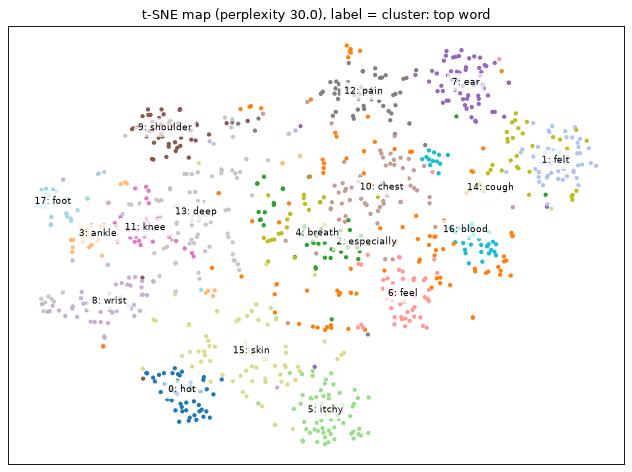

In [14]:
xy, info = treport.project_2d(embedding, random_state=SEED)
fig, ax = plt.subplots(figsize=(8, 6))
ax.scatter(xy[:, 0], xy[:, 1], c=labels, cmap="tab20", s=8)
for c in range(choice.n_clusters):
    cx, cy = np.median(xy[labels == c], axis=0)
    ax.text(cx, cy, f"{c}: {terms[c][0]}", fontsize=8, ha="center", bbox=dict(fc="white", alpha=0.7, lw=0))
ax.set_xticks([]); ax.set_yticks([]); ax.set_title(f"{info['method']} map (perplexity {info.get('perplexity')}), label = cluster: top word")
plt.tight_layout(); plt.show()

#### How to read this output


- Clusters with specific vocabulary form **tight islands**: 0 (hot), 5 (itchy), 9 (shoulder), 7 (ear), 17 (foot), 1 (felt/cold).
- Body-part clusters (3 ankle, 11 knee, 13 hip, 8 wrist, 17 foot) sit on the **same side** of the map: they share words
  like "walking", "sore", "ache". Respiratory ones (1, 14, 4, 10) and skin ones (0, 15, 5) also gather.
- **Orange points (cluster 2) are scattered all over the map**: this confirms that cluster 2 is a catch-all, not a theme.
- Remember the caveats: the distances between islands on this map are not meaningful.

## 11. Running the same pipeline on another CSV

**What we do.** Run the whole chain (sections 2–9) in one call on a different, made-up CSV: semicolon-separated, with a
header, in French, with a category column.

**Why.** To show the tool is not tied to this dataset: nothing above was specific to `Student_Dataset.csv`.

**How it works.** `tpipe.run(csv_path, text_column=None, label_column=None, config=tpipe.Config(...))` does everything.
Every setting of `Config` is optional (`None` = derived from the data): `language` (`"en"`, `"fr"`, `"none"`),
`ngram_range`, `max_components`, `fixed_k`, `k_max_cap`, `max_noise`, `algorithms`. From a terminal:

```
python -m textclust path/to/file.csv [--text-column C] [--label-column C | --no-labels] [--k K] [--language fr] [--output runs]
```

When a label column exists, the clusters are compared with it using the **adjusted Rand index (ARI)** and the
**normalised mutual information (NMI)**: 1 = the clusters match the categories exactly, 0 = no better than chance.

In [15]:
# 36 made-up French testimonies in 3 themes, with their category
themes = {
 "genou": ["mon genou gonfle après la course", "douleur au genou en descendant les escaliers",
           "le genou craque et se bloque quand je plie la jambe", "genou raide le matin et douleur en marchant",
           "je boite car mon genou droit me fait mal", "le genou lâche quand je descends une pente",
           "douleur derrière le genou après le football", "mon genou gauche enfle le soir",
           "impossible de plier le genou sans douleur", "le genou fait mal en montant les marches",
           "après le ski mon genou est douloureux", "mon genou grince et la rotule fait mal"],
 "peau": ["plaques rouges qui grattent sur le bras", "petits boutons rouges et démangeaisons sur la peau",
          "la peau pèle et gratte après le soleil", "rougeur qui gratte sur la main",
          "ma peau est sèche et rouge sur les joues", "des boutons apparaissent et grattent la nuit",
          "éruption rouge sur le ventre qui démange", "la peau du cou est rouge et irritée",
          "des cloques rouges sur la peau des pieds", "ça gratte beaucoup entre les doigts",
          "taches rouges sur la peau après un nouveau savon", "la peau brûle et rougit au soleil"],
 "toux": ["toux sèche depuis trois jours et gorge irritée", "je tousse la nuit avec la gorge qui pique",
          "toux grasse et nez bouché", "gorge douloureuse et toux le soir",
          "je tousse beaucoup en me levant", "la toux ne passe pas depuis une semaine",
          "mal de gorge et petite fièvre avec toux", "je tousse et je crache le matin",
          "la gorge gratte et la toux revient", "toux qui empêche de dormir et gorge sèche",
          "nez qui coule et toux depuis hier", "quinte de toux en parlant et gorge en feu"],
}
rows = [(f"id{k}", theme, text) for k, (theme, text) in enumerate((t, x) for t, xs in themes.items() for x in xs)]
tmp = Path(tempfile.mkdtemp()) / "autre.csv"
pd.DataFrame(rows, columns=["id", "categorie", "temoignage"]).to_csv(tmp, sep=";", index=False)

demo = tpipe.run(tmp, config=tpipe.Config(projection=False), save=False)
prof = demo.metrics["data_profile"]
print("delimiter", repr(prof["delimiter"]), "| header", prof["header"], "| text column", prof["text_column"],
      "| label column", prof["label_column"], "| language", demo.metrics["language_used"])
print("chosen:", demo.algorithm, demo.n_clusters, "clusters | agreement with 'categorie':",
      {k: round(v, 3) for k, v in demo.metrics["external_labels"].items()})
display(demo.clusters.drop(columns="example"))

delimiter ';' | header True | text column temoignage | label column categorie | language fr
chosen: kmeans 3 clusters | agreement with 'categorie': {'ari': 0.768, 'nmi': 0.775, 'homogeneity': 0.774, 'completeness': 0.776}


,cluster,size,top_terms
0,0,12,"genou, douleur, mal, ski, gonfle, douloureux, course, rotule"
1,1,13,"peau, rouges, gratte, rouge, beaucoup, tousse, soleil, doigts"
2,2,11,"toux, gorge, nuit, nez, sèche, passe, semaine, revient"


#### How to read this output


- On this new file the loader detected **`;` as delimiter, a header row, `temoignage` as the text column, `categorie` as a
  label column, and French** — none of it was given.
- K-Means chose **3 clusters** (12, 13 and 11 texts) and the top words are the three themes: **genou/douleur**,
  **peau/rouges/gratte**, **toux/gorge**.
- Agreement with the real categories: **ARI 0.768, NMI 0.775**, high but not perfect: a few texts landed in the wrong group
  (`tousse` appears among the skin words because one cough text was put there). With only 36 short texts, a single word
  shared across themes ("nuit", "rouge") is enough to move a text.

## Summary of the steps

| # | Step | Technique | Key output of this run |
|---|---|---|---|
| 1 | Goal | unsupervised learning: no answers given | find themes in testimonies |
| 2 | Loading | auto-detection of encoding, delimiter, header, ragged rows, text/label columns | 1,011 rows, 397 ragged rows repaired, text = col2, no label column |
| 3 | Cleaning | normalisation, empty/short/duplicate removal, language detection | 994 texts kept (17 duplicates), English |
| 4 | Text → numbers | TF-IDF with stop words, `min_df`/`max_df` from corpus size | 1,271 words (min_df 2, max_df 0.8), 0.98 % non-zero |
| 5 | Compression | truncated SVD (LSA) | 100 components, 41.5 % of variance |
| 6 | Comparing texts | L2 normalisation, cosine similarity | median cosine: 0.02 for random pairs, 0.66 for nearest neighbours |
| 7 | Grouping | K-Means, *k* chosen by silhouette | k = 18, silhouette 0.125 |
| 8 | Alternative | HDBSCAN (density, noise), rejected above 30 % noise | 3 clusters but 77 % noise: rejected |
| 9 | Interpretation | top TF-IDF words per cluster | clear themes (burns, rash, ear, knee, chest…), one catch-all (cluster 2) |
| 10 | Visualisation | t-SNE map | specific themes form islands; cluster 2 is scattered |
| 11 | Generality | same pipeline on another CSV | French CSV with `;`: 3 clusters, ARI 0.77 |

## Conclusion and limitations

**What works.** Without any label, TF-IDF + LSA + K-Means splits ~1,000 testimonies into 18 groups, most of which a reader
names at once from their words (burns, itchy rashes, ear pain, shoulder, knee, chest tightness, blood sugar…). Every
setting is derived from the data (encoding, columns, language, vocabulary filters, *k*), so the same code ran unchanged on a
French, semicolon-separated CSV.

**Limitations.**
- **Weak separation.** The silhouette (0.125) is low and one cluster (2) is a catch-all; themes overlap in real symptoms.
- ***k* is a judgement call.** The silhouette barely differs between k = 16, 18 and 20; another reasonable choice would give
  other splits (e.g. the two respiratory clusters could merge).
- **Bag of words.** TF-IDF ignores word order and meaning: "no fever" and "fever" look alike, and synonyms only partly merge
  through LSA. Sentence embeddings from a language model would capture meaning better, but were outside the allowed libraries.
- **Themes are named by a human** from top words; they are not validated against any medical label for this dataset.
- **Not a diagnostic tool.** Clusters group ways of *describing* symptoms; they say nothing reliable about a person's
  condition.
- **Privacy.** The testimonies stay local; only aggregated words and two truncated examples are published.